# Отчет по анализу задержек авиарейсов



In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12, 6)

try:
    df = pd.read_csv('flights/flights.csv', dtype=str)
except FileNotFoundError:
    # Если файл в текущей папке
    df = pd.read_csv('flights.csv', dtype=str)

df['DEPARTURE_DELAY'] = df['DEPARTURE_DELAY'].astype(float)
df['ARRIVAL_DELAY'] = df['ARRIVAL_DELAY'].astype(float)
df['CANCELLED'] = df['CANCELLED'].astype(int)
df['MONTH'] = df['MONTH'].astype(int)
df['DAY_OF_WEEK'] = df['DAY_OF_WEEK'].astype(int)

print("Данные успешно загружены. Размер:", df.shape)

Данные успешно загружены. Размер: (5819079, 31)


---

### 1. Исследование сезонности задержек

**Описание:** Мы проанализируем, как среднее время задержки вылета (`DEPARTURE_DELAY`) зависит от месяца. Это позволит понять, существуют ли сезонные пики (например, летом или зимой), когда вероятность задержки выше.

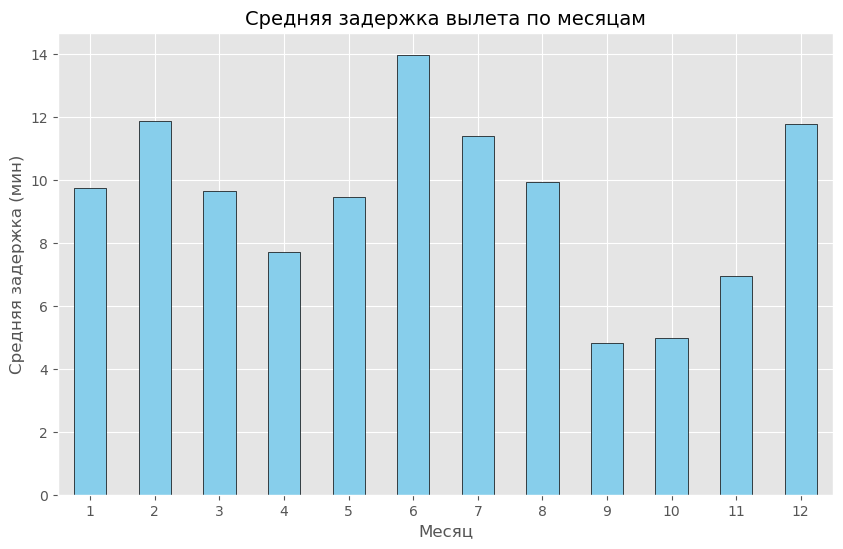

In [17]:
monthly_delay = df.groupby('MONTH')['DEPARTURE_DELAY'].mean()

plt.figure(figsize=(10, 6))
monthly_delay.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Средняя задержка вылета по месяцам', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Средняя задержка (мин)', fontsize=12)
plt.xticks(rotation=0)
plt.show()

**Вывод:** Из графика видно, что наибольшие задержки наблюдаются в летние месяцы (июнь, июль), что вероятно связано с сезоном отпусков и высокой загрузкой аэропортов, а также в декабре и феврале (зимние погодные условия). Осенью (сентябрь, октябрь) задержки минимальны.

---

### 2. Зависимость задержек от дня недели

**Описание:** Проверим, в какие дни недели летать пунктуальнее всего. Дни недели закодированы числами (1 — Понедельник, 7 — Воскресенье). Мы построим график распределения средней задержки по дням.

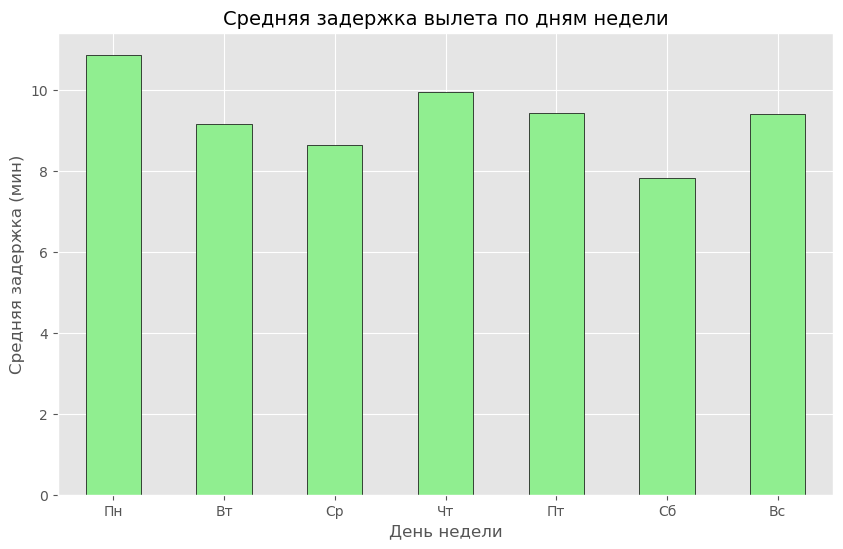

In [18]:
weekly_delay = df.groupby('DAY_OF_WEEK')['DEPARTURE_DELAY'].mean()

days_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

plt.figure(figsize=(10, 6))
weekly_delay.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Средняя задержка вылета по дням недели', fontsize=14)
plt.xlabel('День недели', fontsize=12)
plt.ylabel('Средняя задержка (мин)', fontsize=12)
plt.xticks(ticks=range(7), labels=days_labels, rotation=0)
plt.show()

**Вывод:** График показывает, что понедельник и четверг/пятница — самые загруженные дни с наибольшими задержками. Суббота (6-й день) является наиболее благоприятным днем для полетов с минимальным средним временем ожидания.

---

### 3. Рейтинг авиакомпаний по пунктуальности

**Описание:** Сравним различных авиаперевозчиков по показателю средней задержки вылета. Это поможет определить наиболее и наименее надежные авиакомпании.

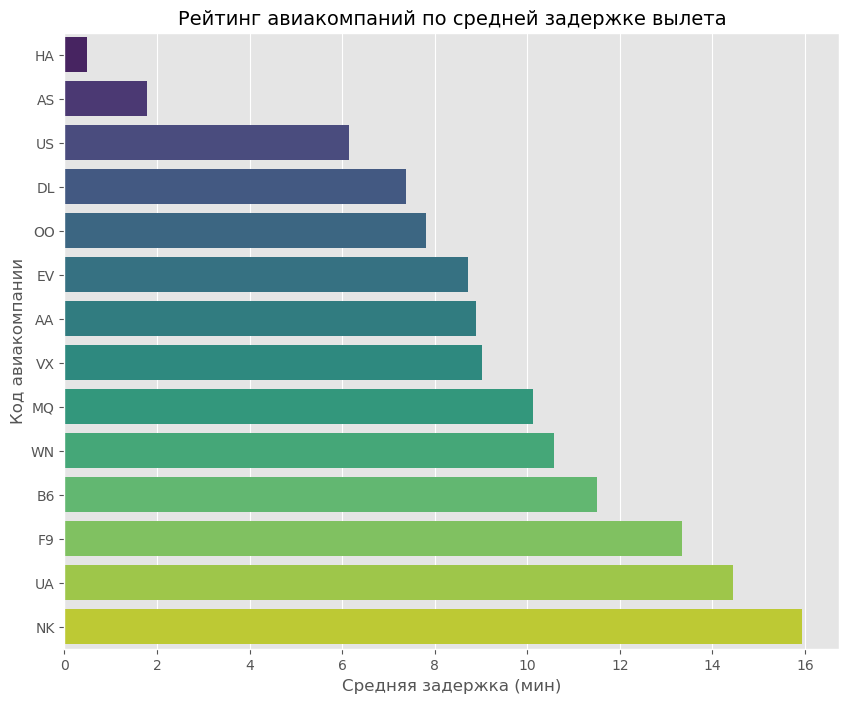

In [19]:
airline_delay = df.groupby('AIRLINE')['DEPARTURE_DELAY'].mean().sort_values()

plt.figure(figsize=(10, 8))
sns.barplot(x=airline_delay.values, y=airline_delay.index, palette='viridis')
plt.title('Рейтинг авиакомпаний по средней задержке вылета', fontsize=14)
plt.xlabel('Средняя задержка (мин)', fontsize=12)
plt.ylabel('Код авиакомпании', fontsize=12)
plt.show()

**Вывод:** Наблюдается значительный разброс между авиакомпаниями. Перевозчики в верхней части графика (например, HA - Hawaiian Airlines) демонстрируют лучшую пунктуальность, тогда как компании внизу списка (например, NK - Spirit Airlines) имеют самые высокие показатели средней задержки.

---

### 4. Динамика задержек в течение суток

**Описание:** Существует гипотеза, что задержки имеют свойство накапливаться в течение дня ("эффект снежного кома"). Мы извлечем час вылета из расписания (`SCHEDULED_DEPARTURE`) и проверим, как меняется средняя задержка от утра к ночи.

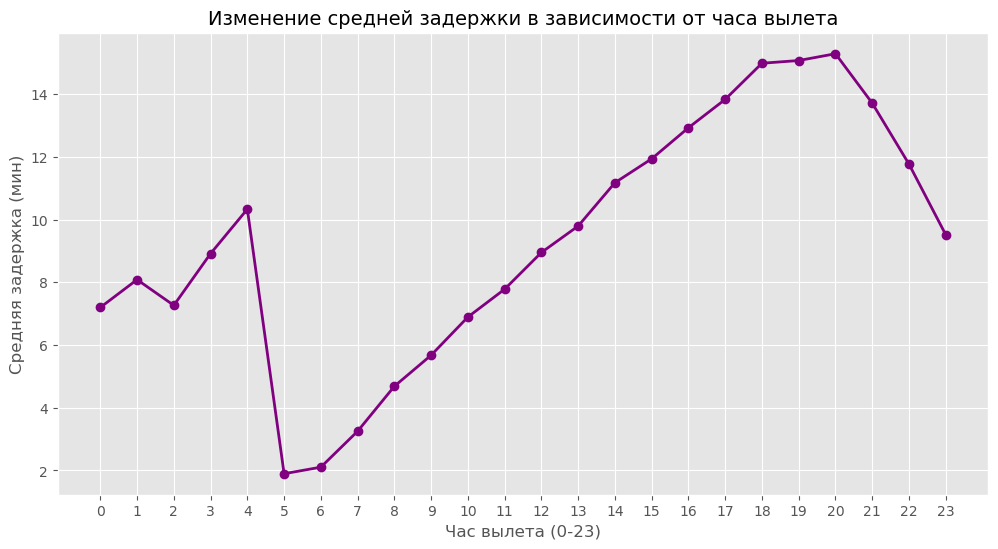

In [20]:
def get_hour(x):
    if pd.isna(x):
        return None
    s = str(x).zfill(4)
    return int(s[:2])


df['HOUR'] = df['SCHEDULED_DEPARTURE'].apply(get_hour)

hourly_delay = df.groupby('HOUR')['DEPARTURE_DELAY'].mean()

plt.figure(figsize=(12, 6))
hourly_delay.plot(kind='line', marker='o', color='purple', linewidth=2)
plt.title('Изменение средней задержки в зависимости от часа вылета', fontsize=14)
plt.xlabel('Час вылета (0-23)', fontsize=12)
plt.ylabel('Средняя задержка (мин)', fontsize=12)
plt.grid(True)
plt.xticks(range(0, 24))
plt.show()

**Вывод:** Гипотеза подтверждается. Утренние рейсы (5:00 - 8:00) вылетают практически без задержек. В течение дня задержки неуклонно растут, достигая пика в вечернее время (19:00 - 21:00), после чего немного снижаются ночью.

---

### 5. Процент отмененных рейсов по авиакомпаниям

**Описание:** Помимо задержек, критическим фактором является отмена рейса. Мы рассчитаем долю отмененных рейсов (`CANCELLED` = 1) для каждой авиакомпании, чтобы выявить наименее надежных перевозчиков в этом аспекте.

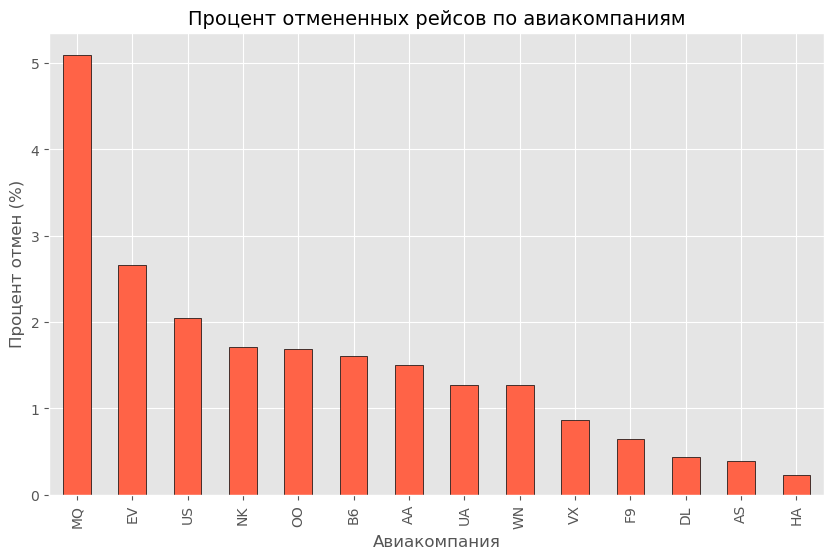

In [21]:
cancellation_rate = df.groupby('AIRLINE')['CANCELLED'].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 6))
cancellation_rate.plot(kind='bar', color='tomato', edgecolor='black')
plt.title('Процент отмененных рейсов по авиакомпаниям', fontsize=14)
plt.xlabel('Авиакомпания', fontsize=12)
plt.ylabel('Процент отмен (%)', fontsize=12)
plt.show()

**Вывод:** График позволяет выделить авиакомпании с наибольшим риском отмены рейса (например, MQ или EV, где процент может превышать 2-3%). Крупные магистральные перевозчики (DL, HA) обычно имеют существенно более низкий процент отмен.